<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 07 · Kubo transport: anomalous, spin and orbital Hall conductivities

$$\sigma^{O}_{ab}=-\frac{e^2}{\hbar}\int\!\frac{d^dk}{(2\pi)^d}\sum_n f_n\,\Omega^{O}_{n,ab},\qquad
\Omega^{O}_{n,ab}=-2\,\mathrm{Im}\sum_{m\ne n}\frac{\langle n|J^O_a|m\rangle\langle m|v_b|n\rangle}{(E_n-E_m)^2+\eta^2},\quad J^O_a=\tfrac12\{O,v_a\}$$

$O=1$: anomalous Hall (AHC); $O=s_z$: spin Hall (SHC); $O=L_z$: orbital Hall (OHC).
Units: 2D in $e^2/h$, 3D in S/cm (Å lengths). The sign convention follows Wannier90.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. Quantised AHC of a Chern insulator, and its μ dependence

sigma^charge_xy = -1 [e^2/h]


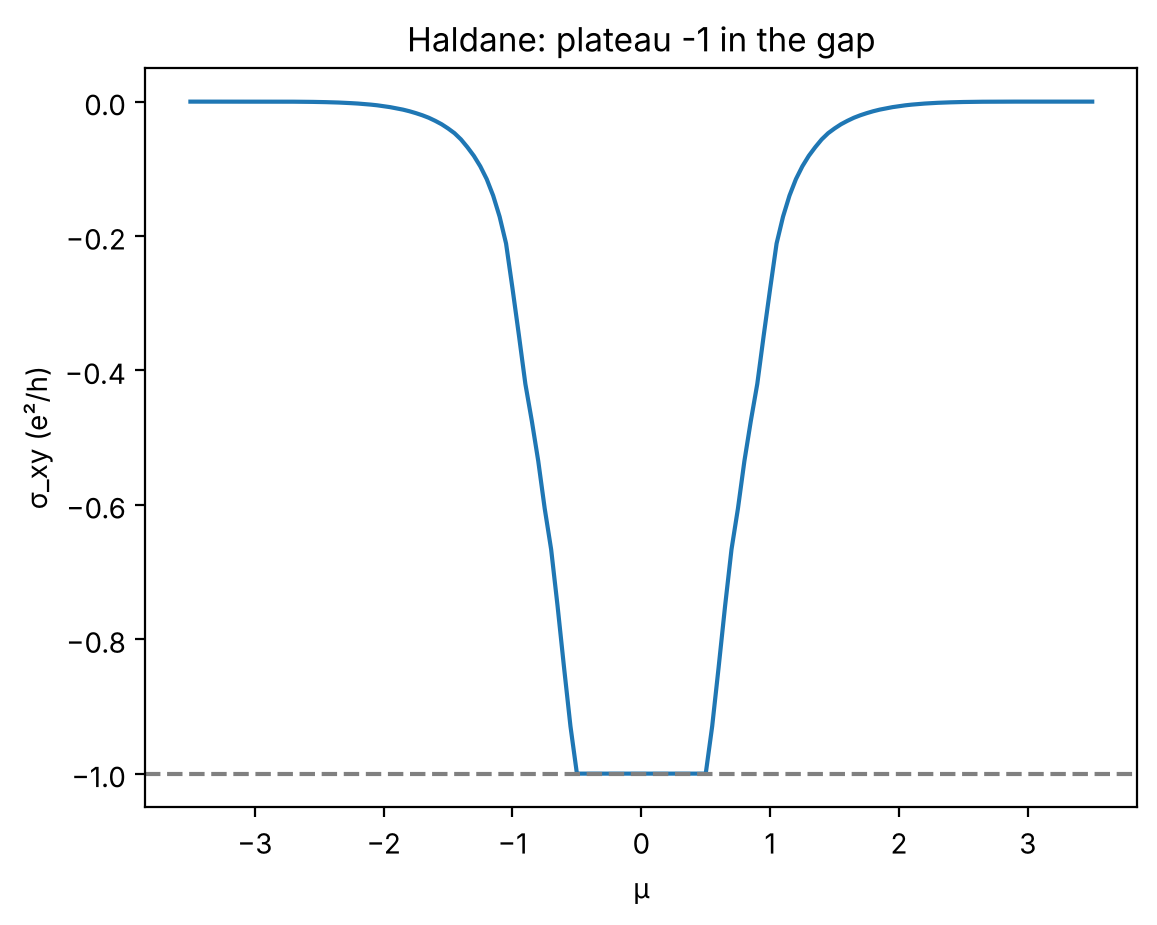

In [2]:
h = M.haldane(t2=0.1)
mus = np.linspace(-3.5, 3.5, 141)
r = hf.anomalous_hall(h, mus, nk=120)
plt.plot(mus, r.sigma); plt.axhline(-1, ls="--", c="gray")
plt.xlabel("μ"); plt.ylabel("σ_xy (e²/h)"); plt.title("Haldane: plateau -1 in the gap");
print(hf.anomalous_hall(h, 0.0, 120))

## 2. Quantised spin Hall conductivity of Kane-Mele

In [3]:
km = M.kane_mele()
print(hf.spin_hall(km, 0.0, 120))
print("with Rashba 0.1:", hf.spin_hall(M.kane_mele(lr=0.1), 0.0, 120), " (no longer exactly quantised)")

sigma^Sz_xy = -1 [(hbar/e) e^2/h]
with Rashba 0.1: sigma^Sz_xy = -1.09938 [(hbar/e) e^2/h]  (no longer exactly quantised)


## 3. AHC of a 2D Rashba ferromagnet (metallic, non-quantised)

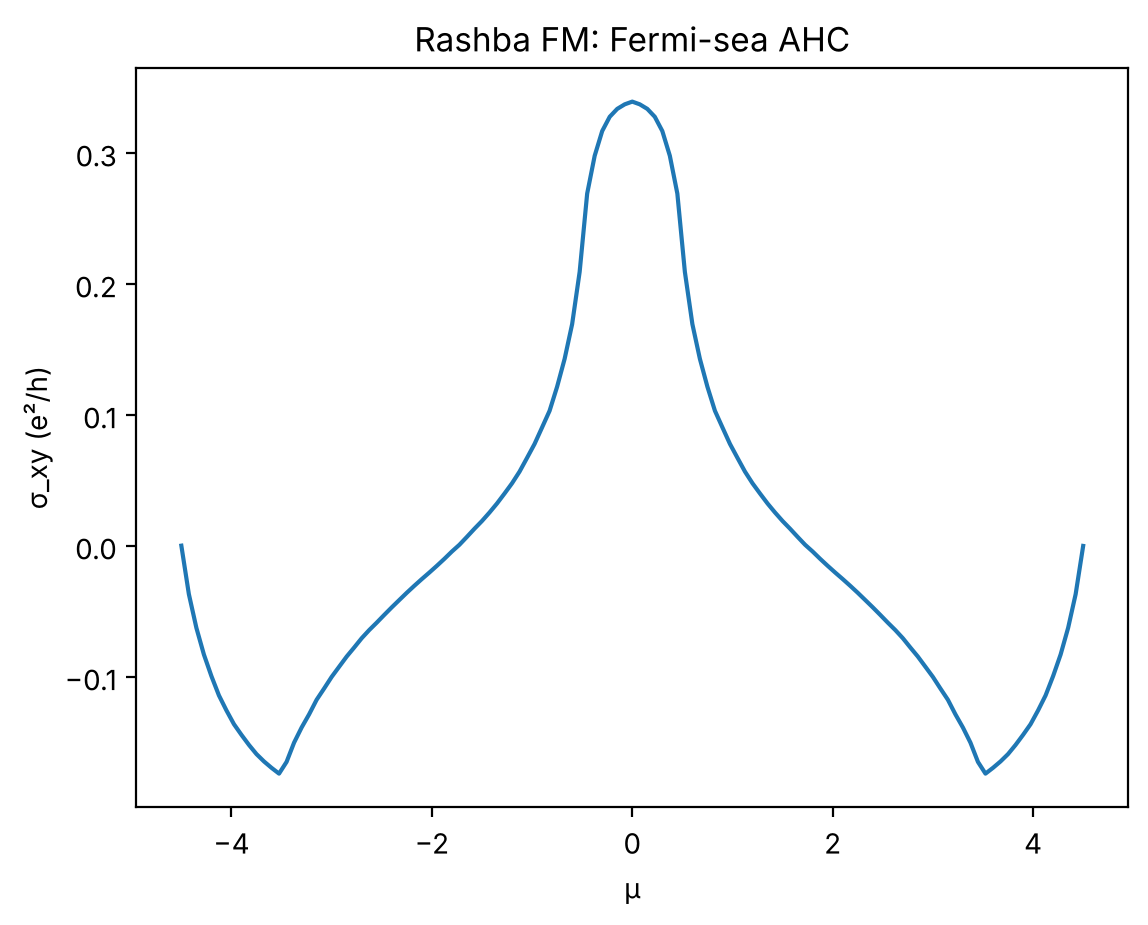

In [4]:
rf = M.rashba_square(alpha=0.3, J=0.5)
mus = np.linspace(-4.5, 4.5, 121)
plt.plot(mus, hf.anomalous_hall(rf, mus, nk=150, eta=0.01).sigma)
plt.xlabel("μ"); plt.ylabel("σ_xy (e²/h)"); plt.title("Rashba FM: Fermi-sea AHC");

## 4. 3D: Weyl semimetal AHC in S/cm
$\sigma_{xy}=\frac{e^2}{h}\frac{\Delta k_z}{2\pi}$ per unit length.

In [5]:
e2h_Scm = 3.874045e-5 * 1e8      # e^2/h per Angstrom in S/cm
for m_ in [1.5, 2.0, 2.5]:
    w = M.weyl_minimal(m_=m_)
    dk = 2*np.arccos(m_ - 2)/(2*np.pi)                     # node separation / (2 pi)
    kubo = float(hf.anomalous_hall(w, 0.0, 60))            # Kubo on a 60^3 mesh
    kz = np.linspace(0, 1, 200, endpoint=False)            # exact: sum of plane Chern numbers
    planes = -np.mean([round(hf.chern_number(w, 1, 40, fixed={2: z})) for z in kz]) * e2h_Scm
    print(f"m={m_}: Kubo {kubo:7.1f}   FHS planes {planes:7.1f}   analytic {dk*e2h_Scm:7.1f}  S/cm")

m=1.5: Kubo  2579.6   FHS planes  2576.2   analytic  2582.7  S/cm


m=2.0: Kubo  1934.6   FHS planes  1937.0   analytic  1937.0  S/cm


m=2.5: Kubo  1289.2   FHS planes  1297.8   analytic  1291.3  S/cm


The Kubo integral converges more slowly near the Weyl nodes (the curvature diverges there), so a dense mesh is needed. Summing FHS Chern numbers plane by plane is exact for each plane, which makes it a useful check.

## 5. Orbital Hall effect without spin-orbit coupling
The p-orbital square lattice: the OHC is large even without SOC; adding SOC converts part of it into a spin Hall current.

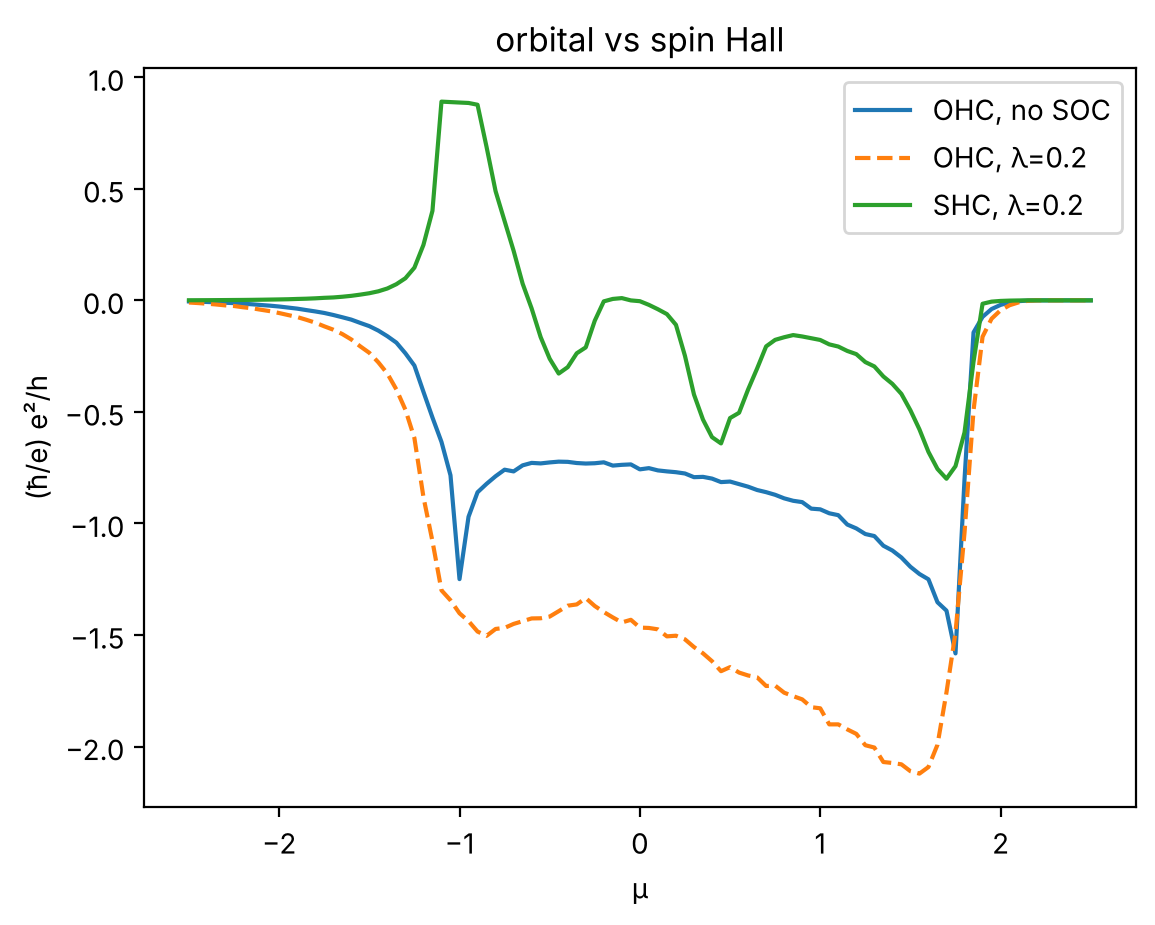

In [6]:
po = M.p_orbital_square()
mus = np.linspace(-2.5, 2.5, 101)
plt.plot(mus, hf.orbital_hall(po, mus, nk=100, eta=0.01).sigma, label="OHC, no SOC")
ps = M.p_orbital_square(lso=0.2)
plt.plot(mus, hf.orbital_hall(ps, mus, nk=100, eta=0.01).sigma, "--", label="OHC, λ=0.2")
plt.plot(mus, hf.spin_hall(ps, mus, nk=100, eta=0.01).sigma, label="SHC, λ=0.2")
plt.legend(); plt.xlabel("μ"); plt.ylabel("(ħ/e) e²/h"); plt.title("orbital vs spin Hall");

## 6. Convergence and broadening

In [7]:
for nk in [20, 40, 80, 160]:
    print(nk, float(hf.anomalous_hall(M.haldane(t2=0.03), 0.0, nk)))

20 -0.945710739409388
40 -0.997094325511499
80 -0.9999996557030807
160 -0.9999999999984496


## Exercises
1. Compute σ_xy of the QWZ model versus m and compare with -C.
2. Show that the AHC of `M.altermagnet_dwave()` vanishes for moments along z but not when Rashba SOC is added with in-plane moments.
3. Converge the SHC of the BHZ model and compare with Kane-Mele.

---
## Quiz 07: Kubo transport

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [8]:
quiz = hf.Quiz(7)
quiz.interactive()

In [9]:
quiz.show()

=== Quiz 07: Kubo transport: anomalous, spin and orbital Hall conductivities ===

Q1. The intrinsic anomalous Hall conductivity is the BZ integral of
   (a) the DOS
   (b) the Berry curvature of occupied states
   (c) the group velocity
   (d) the band energy

Q2. hopforge reports 2D Hall conductivities in units of
   (a) eV
   (b) e^2/h
   (c) Ohm
   (d) S/cm

Q3. For the Haldane model in its C = 1 phase, hopforge's sigma_xy at mu = 0 is
   (a) -1 (Wannier90 sign convention sigma = -C e^2/h)
   (b) 0.5
   (c) +1
   (d) 0

Q4. Moving mu into the conduction band of a Chern insulator makes sigma_xy
   (a) zero always
   (b) infinite
   (c) stay quantised
   (d) deviate from the quantised value (Fermi-sea contribution changes)

Q5. The spin current operator used for the intrinsic SHC is
   (a) s_z v
   (b) {s_z, v_x}/2
   (c) s_z
   (d) v_x only

Q6. Kane-Mele in the QSH phase gives sigma^{s_z}_xy of magnitude
   (a) 2
   (b) 1 (hbar/e) e^2/h = e/2 pi
   (c) 1/2
   (d) 0

Q7. If Rashba SO

In [10]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0